# BudgetBuddy: توقّع آخر الشهر 📈
**من الصفر، خطوة خطوة** (COE305 Week 2: Linear Regression و Gradient Descent)

**السؤال:** اليوم 10 من الشهر، وصرفت 4,200. **قديش رح تكون صارف آخر الشهر؟**

بلغة Week 1: هاد **Supervised Learning → Regression**، لأنه الجواب رقم مش فئة.

| | |
|---|---|
| **Input** | المصروف بكل يوم من أول الشهر لليوم |
| **Output** | مجموع مصروف الشهر كله |
| **المقياس** | **الخطأ النسبي**: \|التوقع − الحقيقة\| ÷ الحقيقة. منستخدم الـ **median** مش الـ mean، عشان كم شهر غريب ما يخربوا الصورة |

### البيانات: Cold start مرة تانية
ما عنا تاريخ مصاريف حقيقي، فعملنا **simulator** (`data/simulate_months.py`) بافتراضات **مكتوبة** وواضحة: إيجار وعائدات أول الشهر، مصاريف يومية صغيرة أكتر بالويكند، شغلة كبيرة كل فترة، وطلاب بيصرفوا أسرع أول الشهر.

⚠️ **أي نتيجة هون صحيحة بقد ما الافتراضات صحيحة.** لما يصير عنا بيانات حقيقية، لازم نعيد الفحص.

3000 months · typical month total 11,418 TRY · days with no spending: 14%


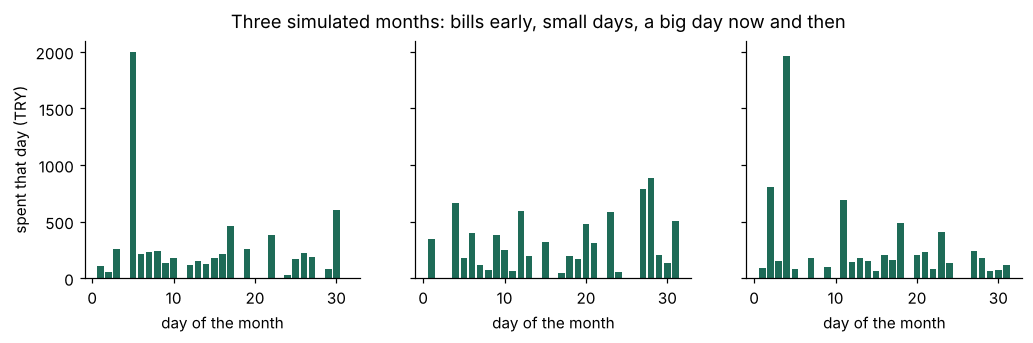

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "../data")
sys.path.insert(0, "../../backend")
from simulate_months import simulate

PINE, MUTED, BERRY, MARIGOLD = "#1e6b57", "#9aa8a3", "#b23c63", "#d9a21b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

D = 31
months = simulate(3000, seed=3)          # 3000 made-up student months
totals = months.sum(axis=1)
print(f"{len(months)} months · typical month total {np.median(totals):,.0f} TRY · "
      f"days with no spending: {(months == 0).mean():.0%}")

fig, axes = plt.subplots(1, 3, figsize=(11, 2.8), sharey=True)
for ax, m in zip(axes, months[[0, 4, 9]]):
    ax.bar(range(1, D + 1), m, color=PINE, width=0.8)
    ax.set_xlabel("day of the month")
axes[0].set_ylabel("spent that day (TRY)")
fig.suptitle("Three simulated months: bills early, small days, a big day now and then")

## الخطوة 1: أبسط حل (baseline)
**"بنفس المعدل لهلق"**: إذا صرفت 4,200 بـ 10 أيام، يعني 420 باليوم، فآخر الشهر 420 × 31 = 13,020.

هاد بالضبط اللي الموقع بيعمله هلق بجملة "عم تصرف أسرع من الشهر". دايماً منبلش بـ baseline، لأنه بدون baseline ما منعرف إذا الموديل "الذكي" فعلاً أحسن.

In [2]:
def error(predictions):
    return np.median(np.abs(predictions - totals) / totals)

def naive(month, d):
    return month[:d].sum() / d * D

CHECK_DAYS = [3, 5, 7, 10, 14, 21, 28]
results = {"same pace (baseline)": [error(np.array([naive(m, d) for m in months])) for d in CHECK_DAYS]}
for d, e in zip(CHECK_DAYS, results["same pace (baseline)"]):
    print(f"day {d:>2}: typical error {e:.0%}")

day  3: typical error 60%
day  5: typical error 59%
day  7: typical error 52%
day 10: typical error 36%
day 14: typical error 24%
day 21: typical error 13%
day 28: typical error 5%


بأول أسبوع الخطأ **أكتر من 50%**! يعني إذا رح تصرف 10,000، ممكن يقلك 15,000 أو 5,000.

## الخطوة 2: Linear Regression من الصفر (Week 2)
الفكرة: منرسم **المجموع التراكمي** (اللي صرفته لحد كل يوم)، ومنمرر فيه **أحسن خط مستقيم**:

$$\hat{y} = w \cdot x + b \qquad x = \text{اليوم},\; \hat{y} = \text{المجموع لهاليوم}$$

الميل $w$ = **قديش بيكلف اليوم العادي**. والتوقع: اللي صرفته + $w$ × الأيام الباقية.

**الـ Loss (MSE):** $J(w, b) = \frac{1}{2n}\sum (\hat{y}_i - y_i)^2$

**الـ Gradient:** $\frac{\partial J}{\partial w} = \frac{1}{n}\sum (\hat{y}_i - y_i)\,x_i \qquad \frac{\partial J}{\partial b} = \frac{1}{n}\sum (\hat{y}_i - y_i)$

### Feature scaling (Week 2) بيفرق كتير

exact slope        315.12 TRY/day
GD, scaled         315.12 TRY/day   (200 steps, lr = 1)
GD, not scaled     314.19 TRY/day   (200 steps, lr = 0.02: not there yet)
GD, not scaled   -1.6e+18 TRY/day   (lr = 0.03: exploded)


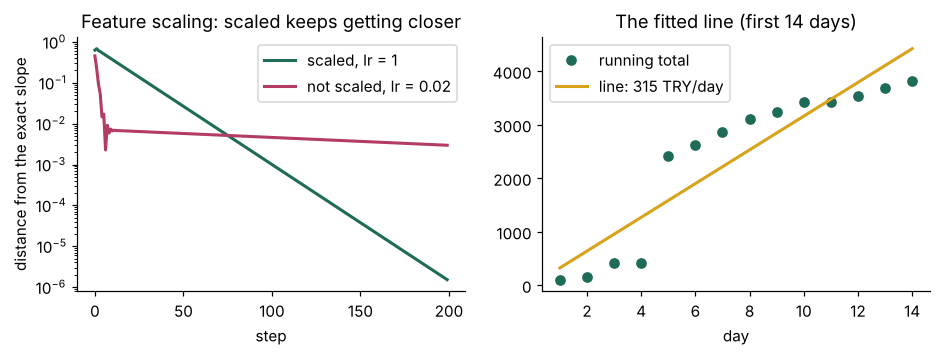

In [3]:
def gradient_descent(x, y, lr, steps):
    w, b, history = 0.0, 0.0, []          # history: w after every step
    for _ in range(steps):
        error_ = w * x + b - y
        w -= lr * (error_ * x).mean()
        b -= lr * error_.mean()
        history.append(w)
    return w, b, history

month = months[0]
d = 14
x = np.arange(1, d + 1, dtype=float)
y = np.cumsum(month[:d])

# Without scaling: x goes up to 14 -> only a small learning rate is stable (0.03 explodes)
w_raw, b_raw, h_raw = gradient_descent(x, y, lr=0.02, steps=200)
w_boom, _, _ = gradient_descent(x, y, lr=0.03, steps=200)
# With scaling (Week 2): x and y between 0 and 1 -> a big learning rate works
xs, ys = x / x.max(), y / y.max()
w_s, b_s, h_s = gradient_descent(xs, ys, lr=1.0, steps=200)
w_scaled = w_s * y.max() / x.max()        # back to TRY per day

# The exact answer (least squares formula), to check both
w_exact = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
print(f"exact slope      {w_exact:8.2f} TRY/day")
print(f"GD, scaled       {w_scaled:8.2f} TRY/day   (200 steps, lr = 1)")
print(f"GD, not scaled   {w_raw:8.2f} TRY/day   (200 steps, lr = 0.02: not there yet)")
print(f"GD, not scaled   {w_boom:8.2g} TRY/day   (lr = 0.03: exploded)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
scale_back = y.max() / x.max()
axes[0].plot(np.abs(np.array(h_s) * scale_back - w_exact) / w_exact, color=PINE, lw=2, label="scaled, lr = 1")
axes[0].plot(np.abs(np.array(h_raw) - w_exact) / w_exact, color=BERRY, lw=2, label="not scaled, lr = 0.02")
axes[0].set_yscale("log"); axes[0].set_xlabel("step"); axes[0].set_ylabel("distance from the exact slope"); axes[0].legend()
axes[0].set_title("Feature scaling: scaled keeps getting closer")
axes[1].plot(x, y, "o", color=PINE, label="running total")
axes[1].plot(x, w_exact * x + (y.mean() - w_exact * x.mean()), color=MARIGOLD, lw=2, label=f"line: {w_exact:.0f} TRY/day")
axes[1].set_xlabel("day"); axes[1].legend(); axes[1].set_title("The fitted line (first 14 days)")

- **بدون scaling:** الـ x لحد 14، فأكبر learning rate بيشتغل هو 0.02 تقريباً (0.03 **بينفجر**). وبعد 200 خطوة لسا ما وصل.
- **مع scaling:** الكل بين 0 و 1، فمنقدر نستخدم lr = 1، وبيوصل للجواب الدقيق بـ 200 خطوة. بالرسم (محور لوغاريتمي): الأخضر بيضل يقرّب لحد ما يصير الفرق تقريباً صفر، والأحمر بيعلق.
- بصراحة: هون الفرق صغير بالرقم النهائي (314 مقابل 315)، لأنه عنا feature وحدة و14 نقطة بس. مع features كتير بمقاييس مختلفة (متل عمر بالسنين ودخل بالآلاف)، بدون scaling ممكن ما يوصل أبداً.
- مع **feature وحدة**، في **قانون دقيق** (least squares) بيعطي نفس الجواب بخطوة وحدة. الـ GD هون عشان نفهم كيف بيتعلم الموديل ونتأكد من القانون.

### هل الـ regression أحسن من الـ baseline؟

In [4]:
def slope(running):
    n = len(running)
    if n < 2:
        return 0.0
    x = np.arange(1, n + 1)
    return ((x - x.mean()) * (running - running.mean())).sum() / ((x - x.mean()) ** 2).sum()

def regression(month, d):
    seen = month[:d]
    return seen.sum() + max(slope(np.cumsum(seen)), 0) * (D - d)

results["regression on the running total"] = [error(np.array([regression(m, d) for m in months])) for d in CHECK_DAYS]
for name, errors in results.items():
    print(f"{name:<34}", "  ".join(f"day {d}: {e:.0%}" for d, e in zip(CHECK_DAYS, errors)))

same pace (baseline)               day 3: 60%  day 5: 59%  day 7: 52%  day 10: 36%  day 14: 24%  day 21: 13%  day 28: 5%
regression on the running total    day 3: 62%  day 5: 59%  day 7: 51%  day 10: 33%  day 14: 21%  day 21: 11%  day 28: 4%


### 😐 تقريباً نفس الشي!
الموديل "الأذكى" ما ساعد. **ليش؟** بدل ما نجرب موديل أعقد، منعمل **error analysis** متل ما عملنا بالتصنيف: منشوف شهر الخطأ فيه كبير.

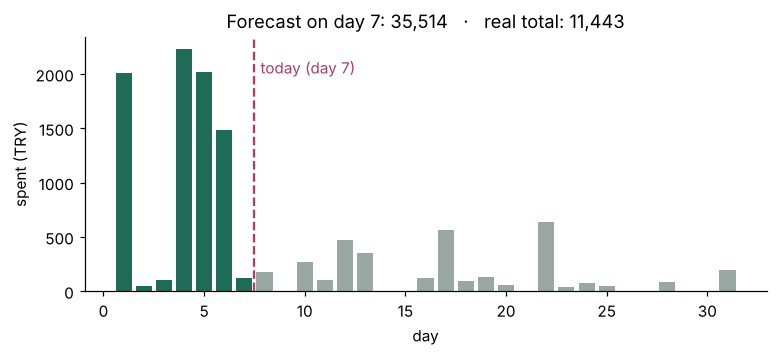

In [5]:
d = 7
errs = np.array([abs(naive(m, d) - t) / t for m, t in zip(months, totals)])
worst = months[np.argsort(-errs)[5]]
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(range(1, D + 1), worst, color=[PINE if i < d else MUTED for i in range(D)])
ax.axvline(d + 0.5, color=BERRY, ls="--"); ax.text(d + 0.8, worst.max() * 0.9, "today (day 7)", color=BERRY)
ax.set_xlabel("day"); ax.set_ylabel("spent (TRY)")
ax.set_title(f"Forecast on day 7: {naive(worst, d):,.0f}   ·   real total: {worst.sum():,.0f}")

### 💡 السبب: الإيجار والعائدات
بأول الشهر في يوم أو يومين **كبار** (إيجار، عائدات، فاتورة). الـ baseline والـ regression الاتنين بيفكروا إنه **كل يوم رح يكون هيك**، فبيضربوه بالأيام الباقية.

بس هاي مصاريف **بتندفع مرة وحدة**. الحل مش موديل أعقد، الحل **feature engineering** (Week 4): نفصل نوعين من الأيام:
- **أيام عادية**: منتوقع إنها تتكرر
- **أيام استثنائية (one-offs)**: يوم أغلى من **3 أضعاف** اليوم العادي (الـ median). منحسبها مرة وحدة (لأنها اندفعت)، وما منكررها

ليش الـ **median** مش الـ mean؟ لأنه الـ mean بيتأثر بالإيجار نفسه، والـ median لأ.

typical error on day:                 3      5      7     10     14     21     28
same pace (baseline)                60%    59%    52%    36%    24%    13%     5%
regression on the running total     62%    59%    51%    33%    21%    11%     4%
one-offs apart, average             51%    40%    28%    20%    14%     8%     3%
one-offs apart, regression          55%    41%    30%    20%    14%     8%     3%


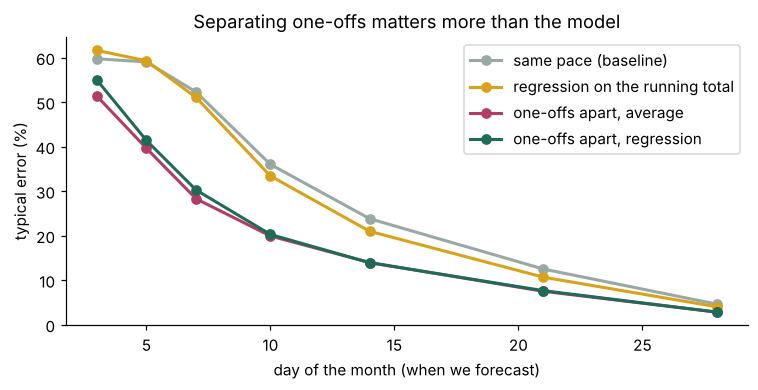

In [6]:
def split_one_offs(seen, factor=3):
    spending_days = seen[seen > 0]
    if len(spending_days) < 3:
        return seen, np.zeros_like(seen)
    big = seen > factor * np.median(spending_days)
    return np.where(big, 0, seen), np.where(big, seen, 0)

def everyday_average(month, d):
    everyday, _ = split_one_offs(month[:d])
    return month[:d].sum() + everyday.mean() * (D - d)

def everyday_regression(month, d):
    everyday, _ = split_one_offs(month[:d])
    return month[:d].sum() + max(slope(np.cumsum(everyday)), 0) * (D - d)

results["one-offs apart, average"] = [error(np.array([everyday_average(m, d) for m in months])) for d in CHECK_DAYS]
results["one-offs apart, regression"] = [error(np.array([everyday_regression(m, d) for m in months])) for d in CHECK_DAYS]

print(f"{'typical error on day:':<32}" + "".join(f"{d:>7}" for d in CHECK_DAYS))
for name, errors in results.items():
    print(f"{name:<32}" + "".join(f"{e:>7.0%}" for e in errors))

fig, ax = plt.subplots(figsize=(8, 3.4))
for (name, errors), color in zip(results.items(), [MUTED, MARIGOLD, BERRY, PINE]):
    ax.plot(CHECK_DAYS, np.array(errors) * 100, "o-", color=color, lw=2, label=name)
ax.set_xlabel("day of the month (when we forecast)"); ax.set_ylabel("typical error (%)"); ax.legend()
ax.set_title("Separating one-offs matters more than the model")

### شو تعلمنا؟
| | |
|---|---|
| **أكبر تحسن** | من **فصل الإيجار والمشتريات الكبيرة** (feature engineering)، مش من الموديل. بيوم 7: من 52% لـ 28% |
| Regression ولا متوسط؟ | **المتوسط أحسن شوي** بأول أسبوع، ومتساويين بعدين. جربت كمان شهور فيها الطالب بيخفف للنص أو بيضاعف من اليوم 8: **نفس النتيجة**، لأنه خط واحد على كل الأيام كمان بيمشي مع المتوسط |
| **القرار** | **المتوسط** (بعد فصل الـ one-offs). أبسط، أسرع، أسهل نشرحه، ومش أسوأ. الـ regression ما زاد شي، فما في سبب نعقّد |
| **إمتى نعرض التوقع؟** | من **اليوم 7**. قبل هيك الخطأ 40% وأكتر، يعني رقم ممكن يضلل أكتر ما يفيد |
| آخر الشهر | الخطأ بيصير صغير (3% بيوم 28)، منطقي لأنه أغلب الشهر صار معروف |

**الدرس:** بالتصنيف كانت المشكلة **البيانات**، وهون كانت **الـ features**. بالحالتين الحل جا من **فهم الأغلاط**، مش من موديل أكبر. وأحياناً الجواب الصح هو **إنك ما تستخدم الموديل الأعقد**، حتى لو بنيته بإيدك. (وهاد اللي كنت كاتبه بجدولك: "التوقع إحصاء ورياضيات، ما بده AI أصلاً" ✅)

**لاحقاً مع بيانات حقيقية:** منعيد الفحص، ومنجرب متوسط **آخر 14 يوم** بس (بيلحق التغير أسرع)، وتاريخ الطالب بالشهور الماضية.

### بالموقع (`backend/app/ml/forecast.py`)
Python عادي، نفس الخطوات بالضبط: فصل الـ one-offs ← متوسط اليوم العادي ← اللي صرفته + المتوسط × الأيام الباقية. ومنتأكد هون إنه بيعطي نفس أرقام الـ notebook:

In [7]:
from app.ml.forecast import forecast_month

d = 10
app = np.array([forecast_month(list(m[:d]), D).total for m in months])
notebook = np.array([everyday_average(m, d) for m in months])
print(f"largest difference between the app and the notebook: {np.abs(app - notebook).max():.6f} TRY")
print(f"on day 6: {forecast_month(list(months[0][:6]), D)}  (too early, no forecast)")
print(f"example on day {d}: {forecast_month(list(months[0][:d]), D)}  · real total {totals[0]:,.0f}")

largest difference between the app and the notebook: 0.000000 TRY
on day 6: None  (too early, no forecast)
example on day 10: Forecast(total=6402.1935778951265, daily_rate=142.15180513840227, one_offs=1995.4876186046572)  · real total 6,614
